# Part 1: Parsing and checking the course's Instagram profile data

The course gave a text file of Instagram profile cards (username, posts, followers, following, name, category, bio) and four questions:

1. Who has the most posts?
2. Who has the most followers?
3. Who follows the most people?
4. How many categories are there, and how many people?

This notebook answers them properly. Then it asks a fifth question the course did not ask: **is this data real?**

**Steps:** read the text → turn each card into a row → check the data → answer the questions → explore → test whether the data is real.

In [1]:
%matplotlib inline
import re
import json
import pandas as pd
import matplotlib.pyplot as plt

# One chart style for the whole project
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})
pd.set_option("display.max_colwidth", 50)

## Step 1: Read the raw text

Each profile is a block of lines (a "card"), and cards are separated by a blank line:

```
username
420 posts
9,800 followers
310 following
Display name
Category          <- not every account has one
Bio lines ...     <- optional
link              <- optional
```

Three cards in this file look like real people or organisations. Before publishing, I replaced their username, name and bio with placeholders (`real_account_1` to `real_account_3`). Their numbers and category are unchanged.

In [2]:
with open("data/course_profiles.txt", encoding="utf-8") as f:
    raw_text = f.read()

# Cards are separated by one or more blank lines
cards = [card.strip() for card in re.split(r"\n\s*\n", raw_text) if card.strip()]

print("Profile cards in the file:", len(cards))
print()
print(cards[0])

Profile cards in the file: 107

techie_koramangala
420 posts
9,800 followers
310 following
Arjun M.
Software Engineer
💻 Full-stack @ SaaS startup
☕ Working from cafes in Koramangala
github.com/arjunmakes


## Step 2: Turn each card into a row

The course code had two parsing problems. Both are fixed here:

- **The category line is optional.** Instagram shows it only for some accounts. The course code always took line 6 as the category, so the first line of a bio could become a "category". Here a line counts as a category only if it looks like one: 1 to 3 plain words, such as "Digital creator" or "Food & Drink".
- **Short numbers like "22.4K" need care.** The course code used `int(22.4 * 1000)`. `int()` cuts off decimals, and computers store decimals slightly inexactly, so `int(32.3 * 1000)` gives **32299** instead of 32300. No count in this file hits that case, but a different file could. `round()` is safe.

Every rule is tested on small made-up cards before it touches the real file.

In [3]:
def parse_count(text):
    """'1,946 posts' -> 1946, '22.4K followers' -> 22400, '1.2M followers' -> 1200000"""
    number = text.split()[0].replace(",", "")
    multiplier = 1
    if number.endswith("K"):
        multiplier, number = 1000, number[:-1]
    elif number.endswith("M"):
        multiplier, number = 1000000, number[:-1]
    return round(float(number) * multiplier)


def looks_like_category(line):
    """Instagram categories are short and plain, e.g. 'Digital creator', 'Food & Drink'."""
    words = line.split()
    plain = all(ch.isalpha() or ch in " &+-" for ch in line)
    return 1 <= len(words) <= 3 and plain


def is_link(line):
    """A link has no spaces and a dot between letters, e.g. 'github.com/someone'."""
    return " " not in line and not line.startswith("@") and re.search(r"\w\.\w", line) is not None


def parse_card(card):
    lines = [line.strip() for line in card.split("\n") if line.strip()]
    profile = {
        "username": lines[0],
        "posts": parse_count(lines[1]),
        "followers": parse_count(lines[2]),
        "following": parse_count(lines[3]),
        "followers_exact": lines[2].split()[0][-1] not in "KM",   # False for '22.4K'
        "name": lines[4] if len(lines) > 4 else "",
    }
    rest = lines[5:]
    if rest and looks_like_category(rest[0]):
        profile["category"], bio_lines = rest[0], rest[1:]
    else:
        profile["category"], bio_lines = "Unknown", rest
    profile["bio"] = " / ".join(bio_lines)
    links = [line for line in bio_lines if is_link(line)]
    profile["link"] = links[-1] if links else ""
    return profile

In [4]:
# Tests on made-up cards (not real accounts)
normal = "demo_cafe\n1 post\n950 followers\n1,234 following\nDemo Cafe\nFood & Drink\nFilter coffee all day\ndemocafe.in"
no_category = "demo_learner\n12 posts\n32.3K followers\n88 following\nDemo Learner\nLearning Python every day, notes below\ngithub.com/demo-learner"
bare = "demo_bot\n0 posts\n1.2M followers\n5 following"

a, b, c = parse_card(normal), parse_card(no_category), parse_card(bare)
assert (a["posts"], a["followers"], a["following"]) == (1, 950, 1234)
assert a["category"] == "Food & Drink" and a["link"] == "democafe.in" and a["followers_exact"]
assert b["followers"] == 32300 and not b["followers_exact"]          # int() would give 32299
assert b["category"] == "Unknown" and b["bio"].startswith("Learning Python")
assert c["followers"] == 1200000 and c["name"] == "" and c["category"] == "Unknown" and c["link"] == ""
print("All parser tests passed")

All parser tests passed


In [5]:
profiles = pd.DataFrame([parse_card(card) for card in cards])
print("Rows:", len(profiles))
profiles.head()

Rows: 107


,username,posts,followers,following,followers_exact,name,category,bio,link
0,techie_koramangala,420,9800,310,True,Arjun M.,Software Engineer,💻 Full-stack @ SaaS startup / ☕ Working from c...,github.com/arjunmakes
1,blrcoder_girl,150,6300,120,True,Riya Codes,Tech Creator,👩‍💻 Python | ML | Roadmaps / 🎥 Coding Reels + ...,linktr.ee/riyacodes
2,hsr_startup_stories,980,22400,95,False,Startup Stories HSR,Media,🚀 Interviews with Bangalore founders / 🎙️ Week...,hsrstartupstories.com
3,cloud_dev_blr,210,4500,60,True,Naveen DevOps,Engineer,☁️ AWS | Docker | K8s / 📍 Sarjapur / github.co...,github.com/naveencloud
4,koramangala_coffee_lover,300,7900,180,True,Sana B.,Cafe Explorer,☕ Reviewing Bangalore’s hidden coffee spots / ...,youtube.com/@sanacafehunter


## Step 3: Check the data

### Repeated usernames
An Instagram username belongs to exactly one account, so the same username twice means a repeated row.

In [6]:
repeats = profiles[profiles.duplicated("username", keep=False)]
print("Usernames that appear twice:", repeats["username"].nunique())
repeats[["username", "posts", "followers", "following", "name", "category"]]

Usernames that appear twice: 2


,username,posts,followers,following,name,category
2,hsr_startup_stories,980,22400,95,Startup Stories HSR,Media
20,machinelearning_blr,490,17800,140,ML Bangalore,Community
62,hsr_startup_stories,600,22000,300,HSR Startup Stories,Media
91,machinelearning_blr,210,19000,250,Machine Learning BLR,Tech


The two copies of each username disagree (for example 22.4K vs 22K followers), so the file itself is inconsistent. I keep the first copy of each.

In [7]:
profiles = profiles.drop_duplicates("username", keep="first").reset_index(drop=True)
print("Unique profiles:", len(profiles))

Unique profiles: 105


### Categories
Many labels mean almost the same thing ("Blog", "Blogger", "Personal Blog"). I group them into broader groups. The grouping is my judgment, written out in full so anyone can check or change it.

In [8]:
CATEGORY_GROUPS = {
    "Community": "Community",
    "Media": "Media & tech pages", "Tech": "Media & tech pages",
    "Blog": "Blogs & writing", "Blogger": "Blogs & writing", "Personal Blog": "Blogs & writing", "Writer": "Blogs & writing",
    "Digital creator": "Creators", "Tech Creator": "Creators", "Comedy": "Creators",
    "Public Figure": "Creators", "Artist + Coder": "Creators",
    "Software Engineer": "Tech professionals", "Engineer": "Tech professionals", "Developer": "Tech professionals",
    "Backend Developer": "Tech professionals", "Frontend Dev": "Tech professionals", "Full-stack Dev": "Tech professionals",
    "Coder": "Tech professionals", "Data Scientist": "Tech professionals", "Data Science": "Tech professionals",
    "Design": "Tech professionals", "Product Manager": "Tech professionals",
    "Entrepreneur": "Business", "Founder": "Business", "Investor": "Business", "Recruiter": "Business",
    "Education": "Education", "Educator": "Education",
    "Food & Drink": "Food & lifestyle", "Lifestyle": "Food & lifestyle",
    "Cafe Explorer": "Food & lifestyle", "Cafe Nerd": "Food & lifestyle",
    "Nonprofit organization": "Non-profit",
}
profiles["category_group"] = profiles["category"].map(CATEGORY_GROUPS).fillna("Other")

print("Different category labels:", profiles["category"].nunique())
print("Labels with no group:", sorted(set(profiles["category"]) - set(CATEGORY_GROUPS)) or "none")
print("Category groups:", profiles["category_group"].nunique())

Different category labels: 34
Labels with no group: none
Category groups: 9


## Step 4: Answer the course's questions

The course code kept a running maximum in a variable called `max`. That name overwrites Python's built-in `max()` function, and the code printed only the username, not the number. pandas does it in one line: `idxmax()` gives the row of the largest value.

In [9]:
def top_account(column):
    row = profiles.loc[profiles[column].idxmax()]
    ties = (profiles[column] == row[column]).sum() - 1
    return row, ties

posts_row, posts_ties = top_account("posts")
followers_row, followers_ties = top_account("followers")
following_row, following_ties = top_account("following")

followers_note = "" if followers_row["followers_exact"] else " (Instagram shows it rounded)"
answers = pd.DataFrame(
    [
        ["Who has the most posts?", posts_row["username"], f"{posts_row['posts']:,} posts"],
        ["Who has the most followers?", followers_row["username"], f"{followers_row['followers']:,} followers{followers_note}"],
        ["Who follows the most people?", following_row["username"], f"{following_row['following']:,} following"],
        ["How many people?", "", f"{len(profiles)} unique profiles"],
        ["How many categories?", "", f"{profiles['category'].nunique()} labels, {profiles['category_group'].nunique()} groups"],
    ],
    columns=["Question", "Account", "Answer"],
)
print("Ties for first place:", posts_ties + followers_ties + following_ties)
answers

Ties for first place: 0


,Question,Account,Answer
0,Who has the most posts?,startuphub_blr,"2,300 posts"
1,Who has the most followers?,real_account_2,"681,000 followers (Instagram shows it rounded)"
2,Who follows the most people?,bangalore_tech_bro,890 following
3,How many people?,,105 unique profiles
4,How many categories?,,"34 labels, 9 groups"


The course notebook read only a 13-profile sample file, so its answers came from 13 profiles. Its "13 categories" also counted "Unknown" and one bio line as categories. The answers above use all the unique profiles.

## Step 5: Explore

In [10]:
median_followers = profiles["followers"].median()
mean_followers = profiles["followers"].mean()
print(f"Median followers: {median_followers:,.0f}")
print(f"Mean followers:   {mean_followers:,.0f}")
print(f"Largest account:  {profiles['followers'].max():,} followers")

Median followers: 6,700
Mean followers:   15,175
Largest account:  681,000 followers


The mean is more than twice the median because one account with about 681,000 followers pulls the average up. For skewed numbers like followers, the **median** describes a typical profile better.

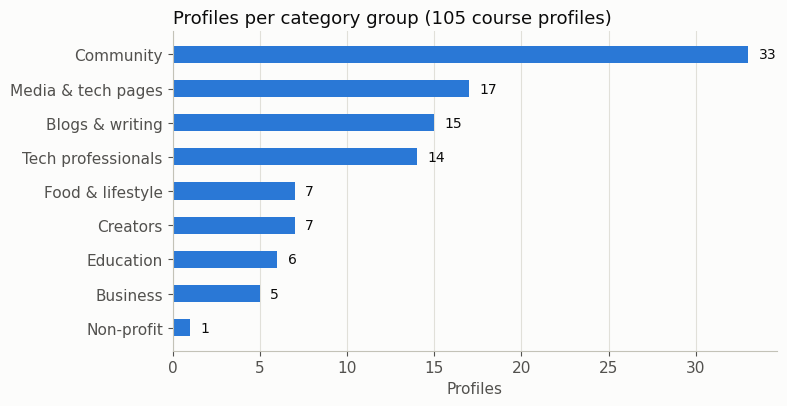

In [11]:
group_counts = profiles["category_group"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(group_counts.index, group_counts.values, color=BLUE, height=0.5)
for y, value in enumerate(group_counts.values):
    ax.text(value + 0.6, y, str(value), va="center", color=INK, fontsize=10)
ax.set_xlabel("Profiles")
ax.grid(axis="y", visible=False)
ax.set_title(f"Profiles per category group ({len(profiles)} course profiles)", loc="left", fontsize=13)
fig.tight_layout()
fig.savefig("images/course_category_groups.png", dpi=150)
plt.show()

In [12]:
def link_type(link):
    if not link:
        return "No link"
    link = link.lower()
    if "google.com/search" in link:
        return "Google search link"
    for key, name in [("github.com", "GitHub"), ("linktr.ee", "Linktree"), ("youtube.com", "YouTube"),
                      ("medium.com", "Medium"), ("bit.ly", "Short link"), ("tinyurl.com", "Short link"),
                      ("strava.com", "Strava")]:
        if key in link:
            return name
    return "Own website"

profiles["link_type"] = profiles["link"].apply(link_type)
profiles["link_type"].value_counts()

link_type
Own website           63
Google search link    11
Short link             8
GitHub                 6
Medium                 6
Linktree               4
No link                3
Strava                 2
YouTube                2
Name: count, dtype: int64

The 3 profiles with no link are the 3 placeholder accounts, whose bio was removed. Keep the 11 Google search links in mind for the next step.

## Step 6: Is this data real?

The course described these profiles as Instagram followers of OpenAI. Three quick checks:

1. **Where are they from?** Followers of a global company should come from many places.
2. **Do the links look normal?**
3. **Are the numbers too round?** In real data, the last two digits of a count are close to random. So about 1 count in 100 ends in "00", and about 1 in 10 ends in "0". I compare with 965 genuine Instagram accounts from the InstaFake research dataset, the real dataset used in Part 2.

In [13]:
BANGALORE_WORDS = ["bangalore", "bengaluru", "blr", "koramangala", "indiranagar", "hsr", "whitefield",
                   "sarjapur", "bellandur", "btm", "jp nagar", "electronic city", "e-city", "ecity",
                   "manyata", "cubbon", "lalbagh", "mg road", "kr puram", "ecoworld", "ecospace", "bagmane"]

def mentions_bangalore(row):
    text = " ".join([row["username"], row["name"], row["bio"]]).lower()
    return any(word in text for word in BANGALORE_WORDS)

profiles["mentions_bangalore"] = profiles.apply(mentions_bangalore, axis=1)
n_bangalore = profiles["mentions_bangalore"].sum()
n_google = (profiles["link_type"] == "Google search link").sum()

print(f"1. Profiles that mention Bangalore or a Bangalore area: {n_bangalore} of {len(profiles)} ({n_bangalore / len(profiles):.0%})")
print(f"2. Profiles whose link is a Google search link instead of a website: {n_google}")

1. Profiles that mention Bangalore or a Bangalore area: 97 of 105 (92%)
2. Profiles whose link is a Google search link instead of a website: 11


In [14]:
with open("data/instafake/realAccountData.json", encoding="utf-8") as f:
    genuine = pd.DataFrame(json.load(f)).drop_duplicates()
print("Genuine Instagram accounts (InstaFake, repeats removed):", len(genuine))

def share_ending_in_zeros(values, zeros):
    return (values % 10 ** zeros == 0).mean()

# Fair comparison: followers between 100 and 9,999 (Instagram shows these in full),
# posts and following of at least 10 (a smaller number can't end in 0 unless it is 0)
course_followers = profiles.loc[profiles["followers_exact"] & profiles["followers"].between(100, 9999), "followers"]
course_posts = profiles.loc[profiles["posts"] >= 10, "posts"]
course_following = profiles.loc[profiles["following"] >= 10, "following"]
real_followers = genuine.loc[genuine["userFollowerCount"].between(100, 9999), "userFollowerCount"]
real_posts = genuine.loc[genuine["userMediaCount"] >= 10, "userMediaCount"]
real_following = genuine.loc[genuine["userFollowingCount"] >= 10, "userFollowingCount"]

round_test = pd.DataFrame(
    {
        "Course data": [share_ending_in_zeros(course_followers, 2), share_ending_in_zeros(course_posts, 1), share_ending_in_zeros(course_following, 1)],
        "Genuine accounts": [share_ending_in_zeros(real_followers, 2), share_ending_in_zeros(real_posts, 1), share_ending_in_zeros(real_following, 1)],
        "Expected by chance": [0.01, 0.10, 0.10],
        "Counts compared (course / genuine)": [f"{len(course_followers)} / {len(real_followers)}", f"{len(course_posts)} / {len(real_posts)}", f"{len(course_following)} / {len(real_following)}"],
    },
    index=["Followers ending in 00", "Posts ending in 0", "Following ending in 0"],
)
print(f"Course follower counts ending in 00: {int((course_followers % 100 == 0).sum())} of {len(course_followers)}")
print(f"Genuine follower counts ending in 00: {int((real_followers % 100 == 0).sum())} of {len(real_followers)}")

table = round_test.copy()
for column in ["Course data", "Genuine accounts", "Expected by chance"]:
    table[column] = table[column].map(lambda v: f"{v:.1%}")
table

Genuine Instagram accounts (InstaFake, repeats removed): 965
Course follower counts ending in 00: 71 of 76
Genuine follower counts ending in 00: 11 of 892


,Course data,Genuine accounts,Expected by chance,Counts compared (course / genuine)
Followers ending in 00,93.4%,1.2%,1.0%,76 / 892
Posts ending in 0,80.0%,9.5%,10.0%,105 / 687
Following ending in 0,74.3%,8.9%,10.0%,105 / 963


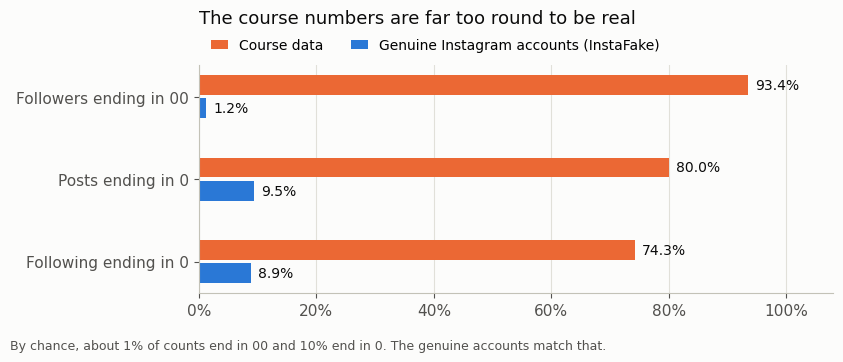

In [15]:
labels = list(round_test.index)
y = range(len(labels))
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.barh([i - 0.14 for i in y], round_test["Course data"], height=0.24, color=ORANGE, label="Course data")
ax.barh([i + 0.14 for i in y], round_test["Genuine accounts"], height=0.24, color=BLUE, label="Genuine Instagram accounts (InstaFake)")
for i in y:
    ax.text(round_test["Course data"].iloc[i] + 0.012, i - 0.14, f"{round_test['Course data'].iloc[i]:.1%}", va="center", color=INK, fontsize=10)
    ax.text(round_test["Genuine accounts"].iloc[i] + 0.012, i + 0.14, f"{round_test['Genuine accounts'].iloc[i]:.1%}", va="center", color=INK, fontsize=10)
ax.set_yticks(list(y))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=10, handlelength=1.2)
ax.set_title("The course numbers are far too round to be real", loc="left", fontsize=13, pad=30)
fig.text(0.012, 0.01, "By chance, about 1% of counts end in 00 and 10% end in 0. The genuine accounts match that.", color=MUTED, fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig("images/round_numbers_test.png", dpi=150)
plt.show()

## Conclusion

Three checks, one answer:

1. **97 of 105 profiles (92%) mention Bangalore** or a Bangalore area. Followers of a global company would come from everywhere.
2. **11 profiles link to a Google search** instead of a website.
3. **71 of 76 follower counts (93.4%) end in 00.** For 892 genuine accounts it is 11 (1.2%), close to the 1% you expect by chance. Posts and following show the same pattern: 80.0% and 74.3% end in 0, against 9.5% and 8.9% for genuine accounts.

So most of the course profiles were made up, probably generated for practice. The file is still useful for practising parsing and cleaning. But any finding about "OpenAI's followers" from it would be false, and checking where data comes from is part of the job.

**That is why Part 2 uses real, labelled data:** `part2_fake_account_detection.ipynb`.